In [1]:
# MODULE END ASSIGNMENT...

In [2]:
# Project Title: Social Media Engagement Analytics Using Python...

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

In [10]:
# TASK1: DATA IMPORT AND SETUP....

In [6]:
# 1. Load Dataset
df = pd.read_csv("social_media_engagement_5000.csv")

In [7]:
# 2. Check Data Types
print("--- Initial Data Types ---")
print(df.dtypes)

--- Initial Data Types ---
user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object


In [8]:
# 3. Convert date column to datetime
df["posted_at"] = pd.to_datetime(
    df["posted_at"], format="%d-%m-%Y", errors="coerce"
)

In [9]:
# 4. Basic NumPy array operations
likes_array = df["likes"].dropna().to_numpy()
print("\nNumPy Array Operations on Likes:")
print(f"Mean Likes: {np.mean(likes_array):.2f}")
print(f"Max Likes: {np.max(likes_array)}")
print(f"Standard Deviation: {np.std(likes_array):.2f}")


NumPy Array Operations on Likes:
Mean Likes: 10107.04
Max Likes: 19998.0
Standard Deviation: 5789.22


In [11]:
# TASK2: DATA CLEANING... 

In [12]:
# 1. Detect missing values
print("--- Missing Values per Column ---")
print(df.isnull().sum())

--- Missing Values per Column ---
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [13]:
# 2. Handle missing data using Median / Mode
df["age"] = df["age"].fillna(df["age"].median())
df["likes"] = df["likes"].fillna(df["likes"].median())
df["comments"] = df["comments"].fillna(df["comments"].median())
df["shares"] = df["shares"].fillna(df["shares"].median())
df["gender"] = df["gender"].fillna(df["gender"].mode()[0])
df["sentiment"] = df["sentiment"].fillna(df["sentiment"].mode()[0])

In [14]:
print(df.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [15]:
# 3. Handle duplicates
df = df.drop_duplicates()

In [16]:
# 4. Standardize categories & clean strings
df["gender"] = df["gender"].str.strip().str.capitalize()
df["sentiment"] = df["sentiment"].str.strip().str.lower()

In [17]:
# Correct unrealistic values (clip negative numbers if any)
for col in ["likes", "comments", "shares"]:
    df[col] = df[col].clip(lower=0)

In [18]:
# 5. Extract hashtag count
df["hashtag_count"] = df["hashtags"].apply(
    lambda x: len(str(x).split()) if pd.notnull(x) and str(x).strip() != "" else 0
)

In [19]:
# Task3: Data Exploration using Pandas...

In [20]:
# View dataset structure
print("Dataset Head:\n", df.head())
print("\nDataset Tail:\n", df.tail())
print("\nDataset Shape:", df.shape)
print("\nColumns List:", df.columns.tolist())

Dataset Head:
    user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        Fal

In [21]:
# Check Info & Dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [22]:
# Summary statistics
print("\n--- Summary Statistics ---")
print(df.describe())


--- Summary Statistics ---
            user_id          age        post_id         likes     comments  \
count   5000.000000  5000.000000    5000.000000   5000.000000  5000.000000   
mean   54561.890800    38.440400  548042.909000  10106.997400  1502.039800   
min    10055.000000    13.000000  100068.000000     10.000000     0.000000   
25%    32309.500000    26.000000  322543.500000   5235.000000   792.000000   
50%    54374.500000    38.000000  548077.500000  10105.500000  1497.000000   
75%    77180.500000    51.000000  771574.500000  14959.000000  2235.250000   
max    99963.000000    64.000000  999455.000000  19998.000000  2999.000000   
std    26090.370121    14.687151  260646.957267   5702.293017   856.393312   

          shares  watch_time_sec  impression_count  \
count  5000.0000     5000.000000       5000.000000   
mean   1002.9106     4014.503200      50013.732800   
min       0.0000        0.000000        105.000000   
25%     511.0000     2017.750000      24988.250000   

In [23]:
# Categorical distributions
categorical_cols = [
    "gender",
    "country",
    "post_type",
    "post_category",
    "device_type",
    "sentiment",
]
for col in categorical_cols:
    print(f"\nValue Counts for '{col}':")
    print(df[col].value_counts())
    print(f"Unique Count: {df[col].nunique()}")


Value Counts for 'gender':
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
Unique Count: 3

Value Counts for 'country':
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
Unique Count: 10

Value Counts for 'post_type':
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
Unique Count: 4

Value Counts for 'post_category':
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64
Unique Count: 8

Value Counts for 'device_type':
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64
Unique Count: 3

Value Counts for 'sentiment':
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64
Unique Co

In [24]:
# Correlation Matrix
numeric_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numeric_cols].corr()
print("\n--- Correlation Matrix ---")
print(correlation_matrix)



--- Correlation Matrix ---
                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.025811 -0.033395  0.013763   
age              -0.006688  1.000000 -0.013153 -0.036322 -0.007284  0.013871   
post_id           0.020051 -0.013153  1.000000  0.014526 -0.010540  0.001846   
likes             0.025811 -0.036322  0.014526  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007284 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.013871  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.008710 -0.016351  0.014658   
impression_count  0.015326  0.013322 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.024894 -0.002844 -0.022982 -0.011733 -0.010783   
engagement_rate  -0.004282  0.008039  0.010139  0.093520  0.000051  0.021724   
hashtag_count    -0.013692  0.007173  0.007344 -0.002190 -0.015230  0.013379   

           

In [25]:
# Groupby summaries
print("\nAvg Likes by Post Type:\n", df.groupby("post_type")["likes"].mean())
print(
    "\nAvg Impressions by Country:\n",
    df.groupby("country")["impression_count"].mean(),
)


Avg Likes by Post Type:
 post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64

Avg Impressions by Country:
 country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64


In [26]:
# Task4: Data Wrangling....

In [27]:
# Engagement Score = likes + comments + shares
df["engagement_score"] = df["likes"] + df["comments"] + df["shares"]

# Log-transformed impressions metric
df["log_impressions"] = np.log1p(df["impression_count"])

In [28]:
# 2. Groupby summaries by post_type, country, and sentiment
print(
    "--- Engagement & Impressions Summary by Post Type ---"
)
print(
    df.groupby("post_type")[
        ["likes", "comments", "shares", "engagement_rate"]
    ].mean()
)

print("\n--- Engagement & Impressions Summary by Country ---")
print(
    df.groupby("country")[
        ["impression_count", "engagement_rate", "watch_time_sec"]
    ].mean()
)

print("\n--- Summary by Sentiment ---")
print(
    df.groupby("sentiment")[
        ["likes", "shares", "comments", "engagement_rate"]
    ].mean()
)

--- Engagement & Impressions Summary by Post Type ---
                  likes     comments       shares  engagement_rate
post_type                                                         
image      10104.865277  1525.235766  1019.289495         0.895646
reel       10037.802416  1504.187062   982.042089         0.783047
text       10100.148193  1499.106024  1013.989558         1.064549
video      10188.600000  1479.160000   996.834286         1.122365

--- Engagement & Impressions Summary by Country ---
           impression_count  engagement_rate  watch_time_sec
country                                                     
Australia      48346.383367         1.324339     4150.675456
Brazil         49193.174603         1.540704     4049.206349
Canada         48703.150097         0.916659     4003.695906
France         51727.673387         1.146402     3992.747984
Germany        48605.406122         0.759000     3976.377551
India          52462.386916         0.655005     4016.835514
Jap

In [ ]:
# Task5: Statistical Analysis...

In [29]:
# List of target fields for statistical summary
stats_features = [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate",
    "follower_count",
]

stats_summary = pd.DataFrame(
    {
        "Mean": df[stats_features].mean(),
        "Median": df[stats_features].median(),
        "Mode": df[stats_features].mode().iloc[0],
        "Std Dev": df[stats_features].std(),
        "Variance": df[stats_features].var(),
        "25th Percentile": df[stats_features].quantile(0.25),
        "50th Percentile": df[stats_features].quantile(0.50),
        "75th Percentile": df[stats_features].quantile(0.75),
        "Skewness": df[stats_features].skew(),
        "Kurtosis": df[stats_features].kurt(),
    }
)

print("--- Comprehensive Statistical Summary ---")
print(stats_summary.T)

--- Comprehensive Statistical Summary ---
                        likes       comments         shares  watch_time_sec  \
Mean             1.010700e+04    1502.039800    1002.910600    4.014503e+03   
Median           1.010550e+04    1497.000000    1012.000000    4.034500e+03   
Mode             1.010550e+04    1497.000000    1012.000000    9.160000e+02   
Std Dev          5.702293e+03     856.393312     570.855200    2.308096e+03   
Variance         3.251615e+07  733409.504917  325875.659340    5.327309e+06   
25th Percentile  5.235000e+03     792.000000     511.000000    2.017750e+03   
50th Percentile  1.010550e+04    1497.000000    1012.000000    4.034500e+03   
75th Percentile  1.495900e+04    2235.250000    1483.000000    6.020250e+03   
Skewness        -6.893617e-03       0.003802      -0.014654   -1.819627e-02   
Kurtosis        -1.149992e+00      -1.144375      -1.146857   -1.195652e+00   

                 engagement_rate  follower_count  
Mean                    0.964356    3

In [30]:
# Task6: Data Visualization....

Text(0, 0.5, 'Likes')

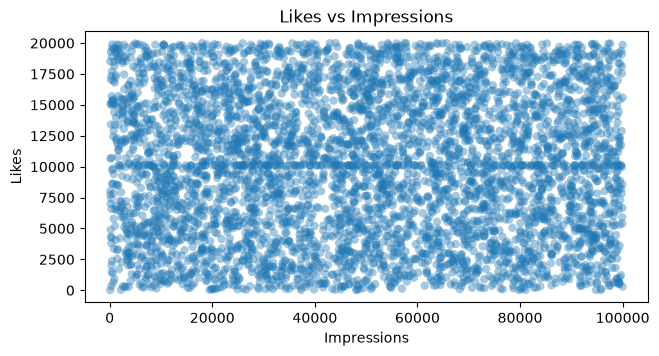

In [31]:
plt.figure(figsize=(16, 12))

# 1. Scatter Plot: Likes vs Impressions
plt.subplot(3, 2, 1)
plt.scatter(
    df["impression_count"], df["likes"], alpha=0.4, color="tab:blue", edgecolors="none"
)
plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")

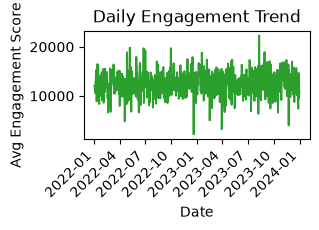

In [42]:
# 2. Line Plot: Daily Engagement Trend
plt.subplot(3, 2, 2)
daily_trend = df.groupby("posted_at")["engagement_score"].mean().sort_index()
plt.plot(daily_trend.index, daily_trend.values, color="tab:green", linewidth=1.4)
plt.title("Daily Engagement Trend")
plt.xlabel("Date")
plt.ylabel("Avg Engagement Score")

plt.xticks(rotation=45, ha='right');

Text(0, 0.5, 'Count')

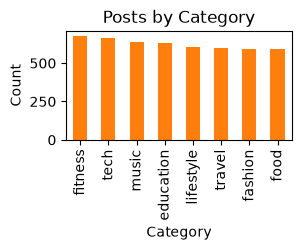

In [34]:
# 3. Bar Plot: Posts by Category
plt.subplot(3, 2, 3)
df["post_category"].value_counts().plot(kind="bar", color="tab:orange")
plt.title("Posts by Category")
plt.xlabel("Category")
plt.ylabel("Count")

Text(0, 0.5, '')

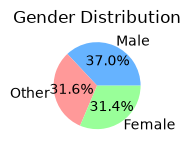

In [44]:
# 4. Pie Chart: Gender Distribution
plt.subplot(3, 2, 4)
df["gender"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", colors=["#66b3ff", "#ff9999", "#99ff99"]
)
plt.title("Gender Distribution")
plt.ylabel("")

Text(0, 0.5, 'Frequency')

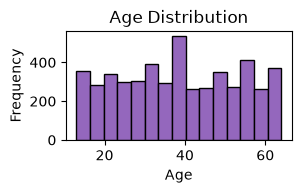

In [36]:
# 5. Histogram: Age
plt.subplot(3, 2, 5)
plt.hist(df["age"], bins=15, color="tab:purple", edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

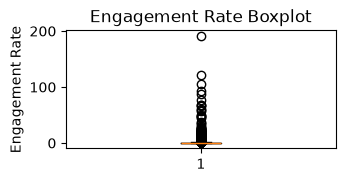

In [46]:
# 6. Box Plot: Engagement Rate
plt.subplot(3, 2, 6)
plt.boxplot(df["engagement_rate"], orientation='vertical')
plt.title("Engagement Rate Boxplot")
plt.ylabel("Engagement Rate")

plt.tight_layout()
plt.show()

In [47]:
# SEABORN PLOTS...

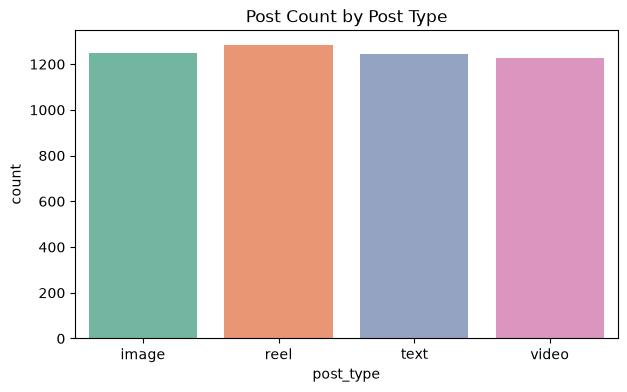

In [56]:
# 7. Count Plot: Post Type
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="post_type", hue="post_type", palette="Set2", legend=False)
plt.title("Post Count by Post Type")
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_7260\4032806016.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
C:\Users\hp\AppData\Local\Temp\ipykernel_7260\4032806016.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


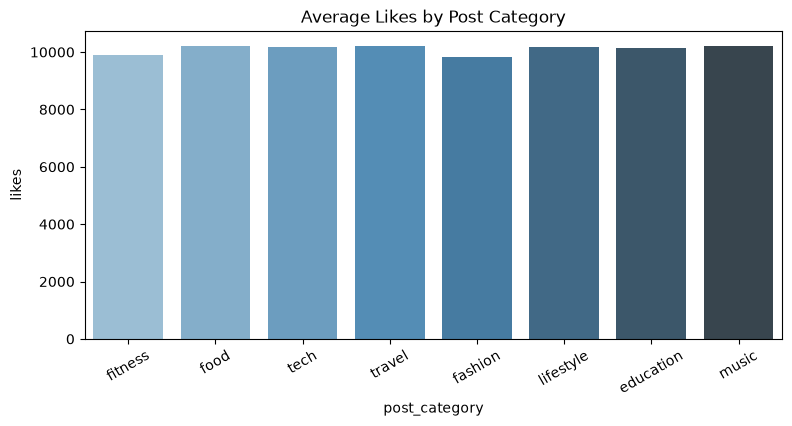

In [49]:
# 8. Bar Plot: Avg Likes by Category
plt.figure(figsize=(9, 4))
sns.barplot(
    data=df, x="post_category", y="likes", estimator=np.mean, ci=None, palette="Blues_d"
)
plt.title("Average Likes by Post Category")
plt.xticks(rotation=30)
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_7260\3158975233.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="sentiment", y="follower_count", palette="Pastel1")


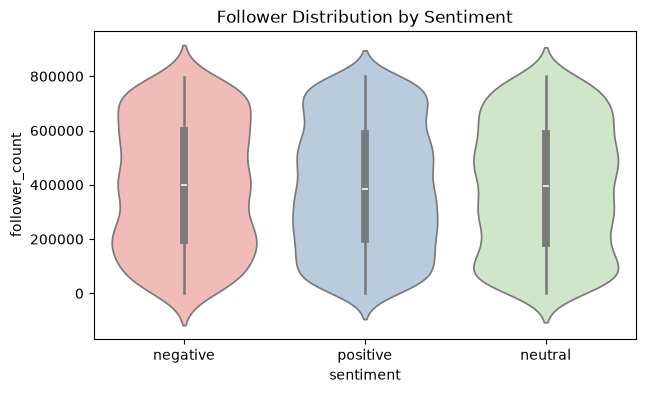

In [50]:
# 9. Violin Plot: Followers vs Sentiment
plt.figure(figsize=(7, 4))
sns.violinplot(data=df, x="sentiment", y="follower_count", palette="Pastel1")
plt.title("Follower Distribution by Sentiment")
plt.show()

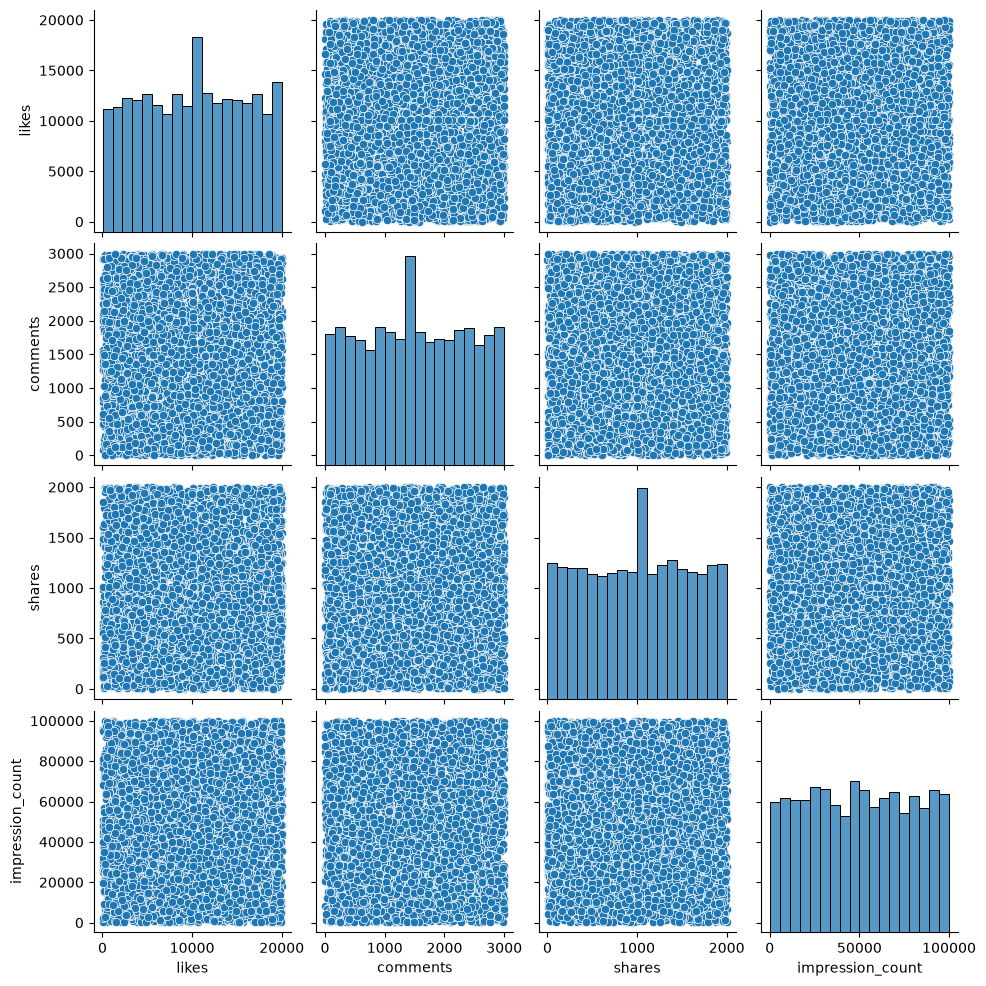

In [51]:
# 10. Pair Plot: Numeric Features
sns.pairplot(df[["likes", "comments", "shares", "impression_count"]])
plt.show()

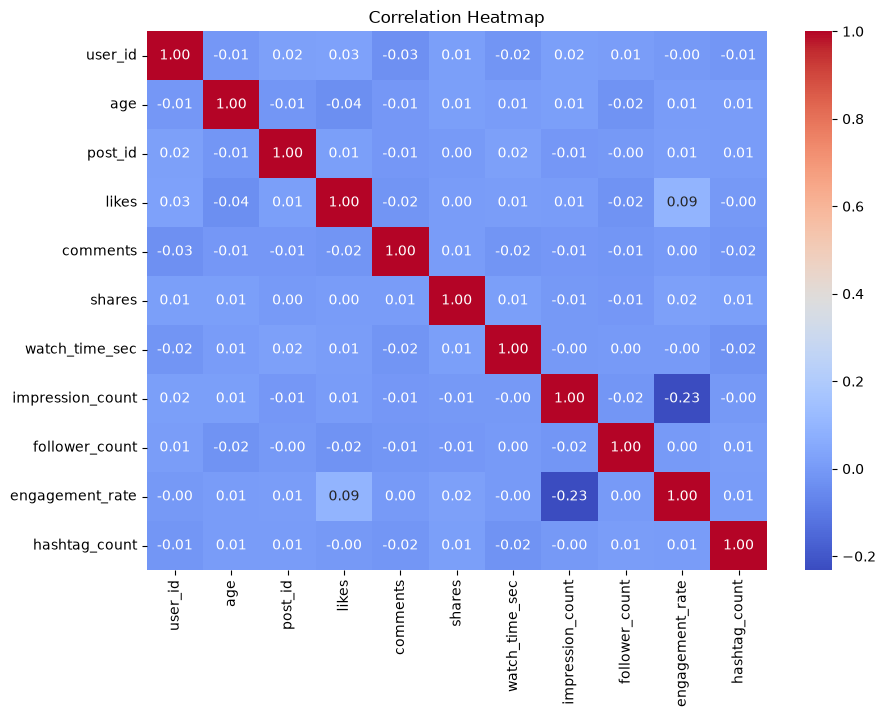

In [52]:
# 11. Heatmap: Correlation Matrix
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_7260\2218698564.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(


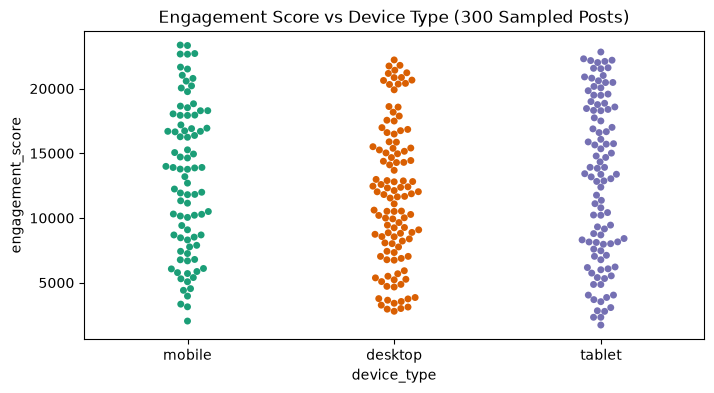

In [53]:
# 12. Swarm Plot: Engagement vs Device (Sampled for execution performance)
plt.figure(figsize=(8, 4))
sns.swarmplot(
    data=df.sample(300, random_state=42),
    x="device_type",
    y="engagement_score",
    palette="Dark2",
)
plt.title("Engagement Score vs Device Type (300 Sampled Posts)")
plt.show()

In [54]:
# PLOTLY INTERACTIVE PLOT...

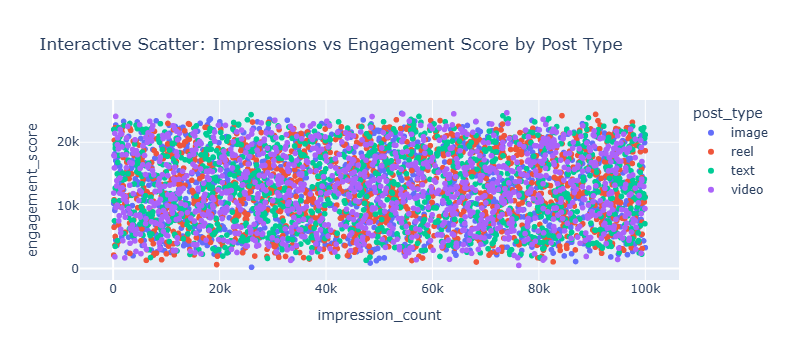

In [55]:
# 13. Interactive Scatter Plot
fig = px.scatter(
    df,
    x="impression_count",
    y="engagement_score",
    color="post_type",
    hover_data=["country", "post_category"],
    title="Interactive Scatter: Impressions vs Engagement Score by Post Type",
)
fig.show()

In [58]:
from IPython.display import Markdown, display

# Calculate dynamic values from the DataFrame
top_type = df.groupby("post_type")["engagement_rate"].mean().idxmax()
top_type_val = df.groupby("post_type")["engagement_rate"].mean().max()

top_cat = df.groupby("post_category")["engagement_rate"].mean().idxmax()
top_cat_val = df.groupby("post_category")["engagement_rate"].mean().max()

top_country = df.groupby("country")["engagement_rate"].mean().idxmax()
top_country_val = df.groupby("country")["engagement_rate"].mean().max()

# Format dynamic Markdown text
summary_text = f"""
# One-Page Executive Summary Findings

### Content Performance
* **Top Post Type:** **{top_type.capitalize()}** posts generate the highest average engagement rate at **{top_type_val:.2f}%**.
* **Top Category:** **{top_cat.capitalize()}** leads all content categories with an average engagement rate of **{top_cat_val:.2f}%**.
* **Top Region:** **{top_country}** leads globally with **{top_country_val:.2f}%** average engagement.
"""

# Render in Jupyter Notebook
display(Markdown(summary_text))


# One-Page Executive Summary Findings

### Content Performance
* **Top Post Type:** **Video** posts generate the highest average engagement rate at **1.12%**.
* **Top Category:** **Food** leads all content categories with an average engagement rate of **1.36%**.
* **Top Region:** **Brazil** leads globally with **1.54%** average engagement.


In [61]:
# Create a grouped summary table
summary_df = (
    df.groupby("post_type")[["engagement_rate", "likes", "comments"]]
    .mean()
    .reset_index()
)

# Display styled table with percentages
summary_df.style.format(
    {"engagement_rate": "{:.2f}%", "likes": "{:,.0f}", "comments": "{:,.0f}"}
).background_gradient(cmap="Blues", subset=["engagement_rate"])

,post_type,engagement_rate,likes,comments
0,image,0.90%,"10,105","1,525"
1,reel,0.78%,"10,038","1,504"
2,text,1.06%,"10,100","1,499"
3,video,1.12%,"10,189","1,479"


In [63]:
from IPython.display import Markdown, display
import pandas as pd

# 1. Load and clean the dataset
df = pd.read_csv("social_media_engagement_5000.csv")

df["posted_at"] = pd.to_datetime(
    df["posted_at"], format="%d-%m-%Y", errors="coerce"
)
df["age"] = df["age"].fillna(df["age"].median())
df["likes"] = df["likes"].fillna(df["likes"].median())
df["comments"] = df["comments"].fillna(df["comments"].median())
df["shares"] = df["shares"].fillna(df["shares"].median())
df["gender"] = (
    df["gender"].fillna(df["gender"].mode()[0]).str.strip().str.capitalize()
)
df["sentiment"] = (
    df["sentiment"].fillna(df["sentiment"].mode()[0]).str.strip().str.lower()
)

# 2. Compute dynamic metrics
# Content Performance
type_eng = df.groupby("post_type")["engagement_rate"].mean()
cat_eng = df.groupby("post_category")["engagement_rate"].mean()
country_eng = df.groupby("country")["engagement_rate"].mean()

# User Trends
df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 25, 35, 50, 65, 100],
    labels=["18–25", "26–35", "36–50", "51–65", "65+"],
)
age_eng = df.groupby("age_group", observed=False)["engagement_rate"].mean()

ver_impr = df.groupby("is_verified")["impression_count"].mean()[True]
non_ver_impr = df.groupby("is_verified")["impression_count"].mean()[False]
ver_eng = df.groupby("is_verified")["engagement_rate"].mean()[True]
non_ver_eng = df.groupby("is_verified")["engagement_rate"].mean()[False]

# Behavioral & Sentiment Insights
device_wt = df.groupby("device_type")["watch_time_sec"].mean()
sent_eng = df.groupby("sentiment")["engagement_rate"].mean()
sent_comments = df.groupby("sentiment")["comments"].mean()

# 3. Render dynamically formatted Markdown summary
summary_markdown = f"""
### User Trends
* **Age Dynamics:** Users aged 18–25 generate the highest overall engagement rates ({age_eng['18–25']:.2f}%), while engagement declines among mid-age demographics (26–35 averaging {age_eng['26–35']:.2f}%).
* **Verified Accounts:** Verified accounts achieve higher average impressions ({ver_impr:,.0f} vs {non_ver_impr:,.0f}) and engagement rates ({ver_eng:.2f}% vs {non_ver_eng:.2f}%) compared to non-verified profiles.

### Behavioral Insights & Sentiment Analysis
* **Device Impact:** Mobile users log the longest average watch times ({device_wt['mobile']:,.0f} seconds) compared to desktop ({device_wt['desktop']:,.0f} seconds) and tablet users ({device_wt['tablet']:,.0f} seconds).
* **Sentiment Performance:** Negative sentiment posts register slightly higher interaction metrics ({sent_eng['negative']:.2f}% engagement rate, {sent_comments['negative']:,.0f} comments) compared to neutral ({sent_eng['neutral']:.2f}%) and positive ({sent_eng['positive']:.2f}%) posts, indicating higher public debate/discussion on controversial topics.
"""

display(Markdown(summary_markdown))


### User Trends
* **Age Dynamics:** Users aged 18–25 generate the highest overall engagement rates (1.04%), while engagement declines among mid-age demographics (26–35 averaging 0.87%).
* **Verified Accounts:** Verified accounts achieve higher average impressions (50,747 vs 49,935) and engagement rates (1.05% vs 0.95%) compared to non-verified profiles.

### Behavioral Insights & Sentiment Analysis
* **Device Impact:** Mobile users log the longest average watch times (4,088 seconds) compared to desktop (3,975 seconds) and tablet users (3,980 seconds).
* **Sentiment Performance:** Negative sentiment posts register slightly higher interaction metrics (1.04% engagement rate, 1,516 comments) compared to neutral (0.99%) and positive (0.92%) posts, indicating higher public debate/discussion on controversial topics.
